# NASA C-MAPSS Exploratory Data Analysis (FD001–FD004)

This notebook performs data-quality checks and exploratory analysis of all four C-MAPSS subsets. FD001 receives the detailed walkthrough; FD002–FD004 are analyzed with comparable summaries and plots. The notebook does **not** train a predictive model.

Each row represents one engine cycle: unit ID, cycle, three operating settings, and 21 sensors. Training trajectories run to failure; test trajectories stop before failure and are paired with one RUL label per engine. Because FD002/FD004 contain multiple operating regimes, a raw sensor shift is not automatically evidence of degradation.

**Run cells from top to bottom.** The default data directory is `./CMAPSSData`; change `DATA_DIR` below if your data folder is elsewhere.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titleweight"] = "bold"

# Prefer a CMAPSSData folder next to the notebook/current working directory.
DATA_DIR = Path("CMAPSSData")
if not DATA_DIR.exists():
    candidates = [Path.cwd() / "CMAPSSData", Path.cwd().parent / "CMAPSSData"]
    DATA_DIR = next((p for p in candidates if p.is_dir()), DATA_DIR)
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Could not find CMAPSSData. Current directory: {Path.cwd()}. "
        "Set DATA_DIR to the folder containing train_FD001.txt, etc."
    )

SUBSETS = ["FD001", "FD002", "FD003", "FD004"]
SETTING_COLS = [f"setting_{i}" for i in range(1, 4)]
SENSOR_COLS = [f"sensor_{i}" for i in range(1, 22)]
COLS = ["unit", "cycle", *SETTING_COLS, *SENSOR_COLS]
DATA_DIR.resolve()

WindowsPath('C:/Users/devan/Downloads/casestudy1sol/CMAPSSData')

## 1. Load files and validate the expected schema

The expected width is 26 columns. The loader preserves one row per unit-cycle observation and reads the supplied test RUL file as one target per test engine. Critical schema or label-count mismatches stop analysis rather than being silently repaired.

In [2]:
datasets = {}
quality_rows = []

def read_cmapss(path):
    frame = pd.read_csv(path, sep=r"\s+", header=None)
    if frame.shape[1] != len(COLS):
        raise ValueError(f"{path.name}: expected 26 columns, found {frame.shape[1]}")
    frame.columns = COLS
    return frame

for subset in SUBSETS:
    train = read_cmapss(DATA_DIR / f"train_{subset}.txt")
    test = read_cmapss(DATA_DIR / f"test_{subset}.txt")
    rul = pd.read_csv(DATA_DIR / f"RUL_{subset}.txt", sep=r"\s+", header=None).iloc[:, 0]
    rul = rul.astype(int).reset_index(drop=True)
    test_units = test["unit"].nunique()
    if test_units != len(rul):
        raise ValueError(
            f"{subset}: {test_units} test engines but {len(rul)} RUL labels. "
            "RUL rows must align with sorted test unit IDs."
        )
    datasets[subset] = {"train": train, "test": test, "rul": rul}

    for split, frame in [("train", train), ("test", test)]:
        key_duplicates = int(frame.duplicated(["unit", "cycle"]).sum())
        # Preserve file order so this detects out-of-order cycles rather than sorting them away.
        cycle_diff = frame.groupby("unit")["cycle"].diff()
        non_increasing = int((cycle_diff.dropna() <= 0).sum())
        quality_rows.append({
            "subset": subset, "split": split, "rows": len(frame),
            "engines": frame["unit"].nunique(),
            "missing_cells": int(frame.isna().sum().sum()),
            "nonfinite_cells": int((~np.isfinite(frame.select_dtypes(include=np.number))).sum().sum()),
            "duplicate_unit_cycle": key_duplicates,
            "non_increasing_cycles": non_increasing,
            "cycle_min": int(frame["cycle"].min()), "cycle_max": int(frame["cycle"].max()),
        })

quality = pd.DataFrame(quality_rows)
print(f"Data directory: {DATA_DIR.resolve()}")
display(quality)
print("All train/test files loaded; test engine counts match RUL label counts.")

Data directory: C:\Users\devan\Downloads\casestudy1sol\CMAPSSData


,subset,split,rows,engines,missing_cells,nonfinite_cells,duplicate_unit_cycle,non_increasing_cycles,cycle_min,cycle_max
0,FD001,train,20631,100,0,0,0,0,1,362
1,FD001,test,13096,100,0,0,0,0,1,303
2,FD002,train,53759,260,0,0,0,0,1,378
3,FD002,test,33991,259,0,0,0,0,1,367
4,FD003,train,24720,100,0,0,0,0,1,525
5,FD003,test,16596,100,0,0,0,0,1,475
6,FD004,train,61249,249,0,0,0,0,1,543
7,FD004,test,41214,248,0,0,0,0,1,486


All train/test files loaded; test engine counts match RUL label counts.


### Interpretation: initial quality gate

Review `missing_cells`, `nonfinite_cells`, duplicate unit-cycle keys, and cycle ordering before interpreting any trend. Unit IDs are local to each subset. The RUL vectors correspond to test engines ordered by unit ID, so the notebook uses sorted unit IDs when attaching labels.

,subset,split,rows,engines,median_cycles,min_cycles,max_cycles
0,FD001,train,20631,100,199.0,128,362
1,FD001,test,13096,100,133.5,31,303
2,FD002,train,53759,260,199.0,128,378
3,FD002,test,33991,259,132.0,21,367
4,FD003,train,24720,100,220.5,145,525
5,FD003,test,16596,100,148.0,38,475
6,FD004,train,61249,249,234.0,128,543
7,FD004,test,41214,248,153.5,19,486


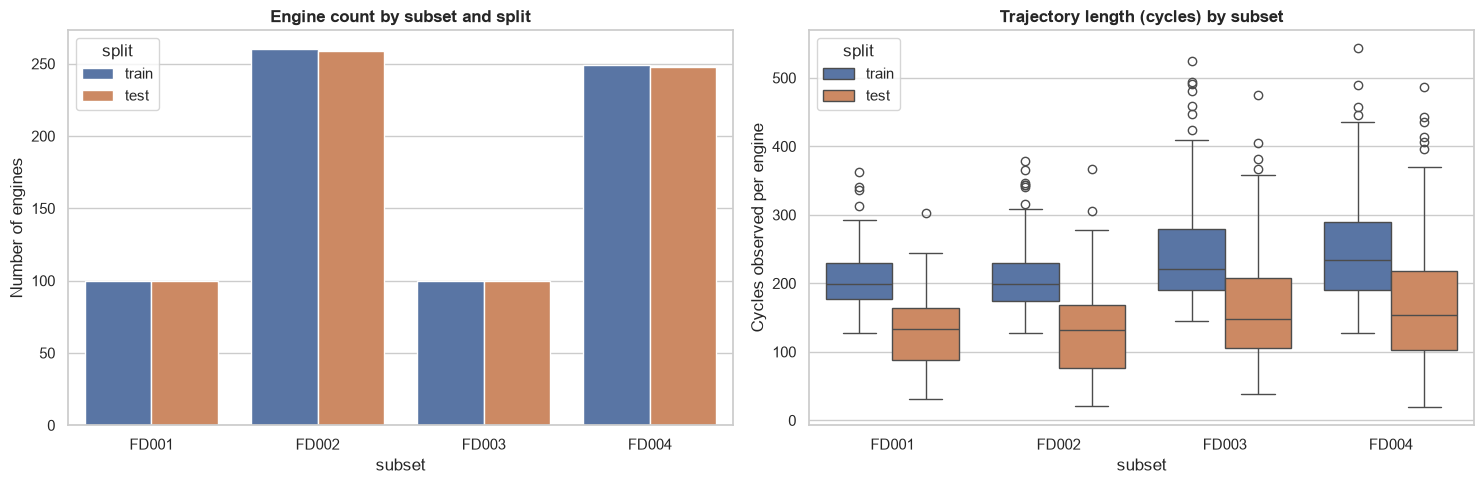

In [3]:
# Per-engine trajectory lengths and high-level subset inventory.
inventory = []
length_frames = []
for subset, parts in datasets.items():
    for split in ["train", "test"]:
        frame = parts[split]
        lengths = frame.groupby("unit")["cycle"].agg(cycles="max", first_cycle="min")
        lengths["subset"] = subset
        lengths["split"] = split
        length_frames.append(lengths.reset_index())
        inventory.append({
            "subset": subset, "split": split, "rows": len(frame),
            "engines": frame.unit.nunique(),
            "median_cycles": lengths.cycles.median(),
            "min_cycles": lengths.cycles.min(), "max_cycles": lengths.cycles.max(),
        })
lengths_all = pd.concat(length_frames, ignore_index=True)
inventory = pd.DataFrame(inventory)
display(inventory.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=inventory, x="subset", y="engines", hue="split", ax=axes[0])
axes[0].set_title("Engine count by subset and split")
axes[0].set_ylabel("Number of engines")
sns.boxplot(data=lengths_all, x="subset", y="cycles", hue="split", ax=axes[1])
axes[1].set_title("Trajectory length (cycles) by subset")
axes[1].set_ylabel("Cycles observed per engine")
plt.tight_layout()
plt.show()

## 2. Operating settings and subset complexity

FD001 and FD003 are single-regime subsets; FD002 and FD004 contain six operating conditions. Settings are visualized separately from sensors because changes in operating regime can create sensor shifts without representing degradation. The scatter plot shows the operating-setting space; it is exploratory and is not a formal regime classifier.

setting_1                  setting_2                 setting_3  \
            mean      std nunique      mean     std nunique      mean   
subset                                                                  
FD001    -0.0000   0.0022     158    0.0000  0.0003      13  100.0000   
FD002    23.9984  14.7474     536    0.5721  0.3100     105   94.0460   
FD003    -0.0000   0.0022     160    0.0000  0.0003      14  100.0000   
FD004    23.9998  14.7807     536    0.5713  0.3107     105   94.0316   

                         
            std nunique  
subset                   
FD001    0.0000       1  
FD002   14.2377       2  
FD003    0.0000       1  
FD004   14.2520       2

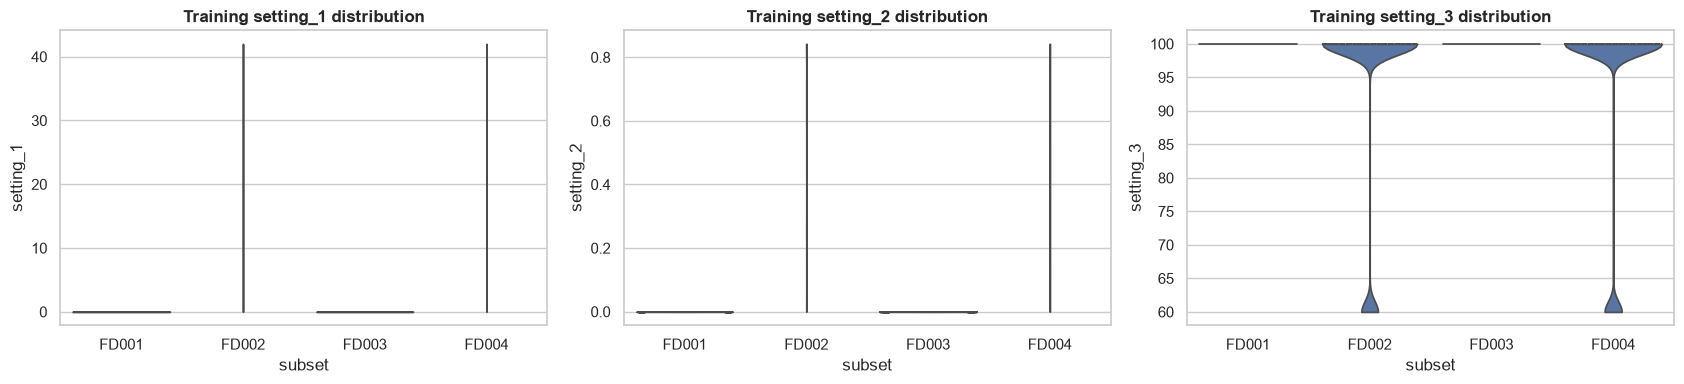

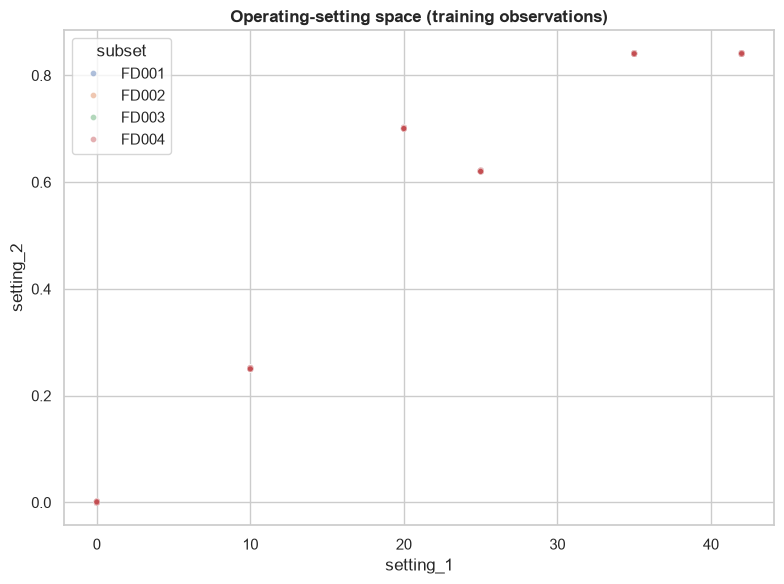

In [4]:
train_combined = pd.concat(
    [parts["train"].assign(subset=subset) for subset, parts in datasets.items()],
    ignore_index=True,
)
setting_summary = train_combined.groupby("subset")[SETTING_COLS].agg(["mean", "std", "nunique"])
display(setting_summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for i, col in enumerate(SETTING_COLS):
    sns.violinplot(data=train_combined, x="subset", y=col, inner="quartile", cut=0, ax=axes[i])
    axes[i].set_title(f"Training {col} distribution")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
sample = train_combined.groupby("subset", group_keys=False).apply(
    lambda g: g.sample(min(len(g), 5000), random_state=7), include_groups=False
).reset_index(drop=True)
# Restore subset labels after groupby/apply for older pandas behavior.
if "subset" not in sample.columns:
    sample = pd.concat([
        g.sample(min(len(g), 5000), random_state=7) for _, g in train_combined.groupby("subset")
    ], ignore_index=True)
sns.scatterplot(data=sample, x="setting_1", y="setting_2", hue="subset", alpha=0.45, s=18, ax=ax)
ax.set_title("Operating-setting space (training observations)")
plt.tight_layout()
plt.show()

## 3. Sensor variability and constant-sensor screening

A sensor that is constant or nearly constant within a subset provides little direct degradation signal there. The table and chart below quantify per-sensor standard deviation for each training subset. This is a screening step only: low variance does not by itself prove that a sensor should be removed, especially before validating train/test consistency and operating-condition effects.

subset,FD001,FD002,FD003,FD004
sensor,,,,
sensor_1,0.00000,26.38971,0.00000,26.43683
sensor_10,0.00000,0.12747,0.00348,0.12768
sensor_11,0.26709,3.23237,0.30007,3.24349
sensor_12,0.73755,137.65951,3.25531,138.47911
sensor_13,0.07192,128.06827,0.15812,128.19786
sensor_14,19.07618,84.83795,16.50412,85.67054
sensor_15,0.03751,0.74934,0.06051,0.75037
sensor_16,0.00000,0.00471,0.00000,0.00468
sensor_17,1.54876,27.75452,1.76146,27.80828


Sensors with std <= 1e-08 by subset:
  FD001: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
  FD002: none
  FD003: ['sensor_1', 'sensor_5', 'sensor_16', 'sensor_18', 'sensor_19']
  FD004: none


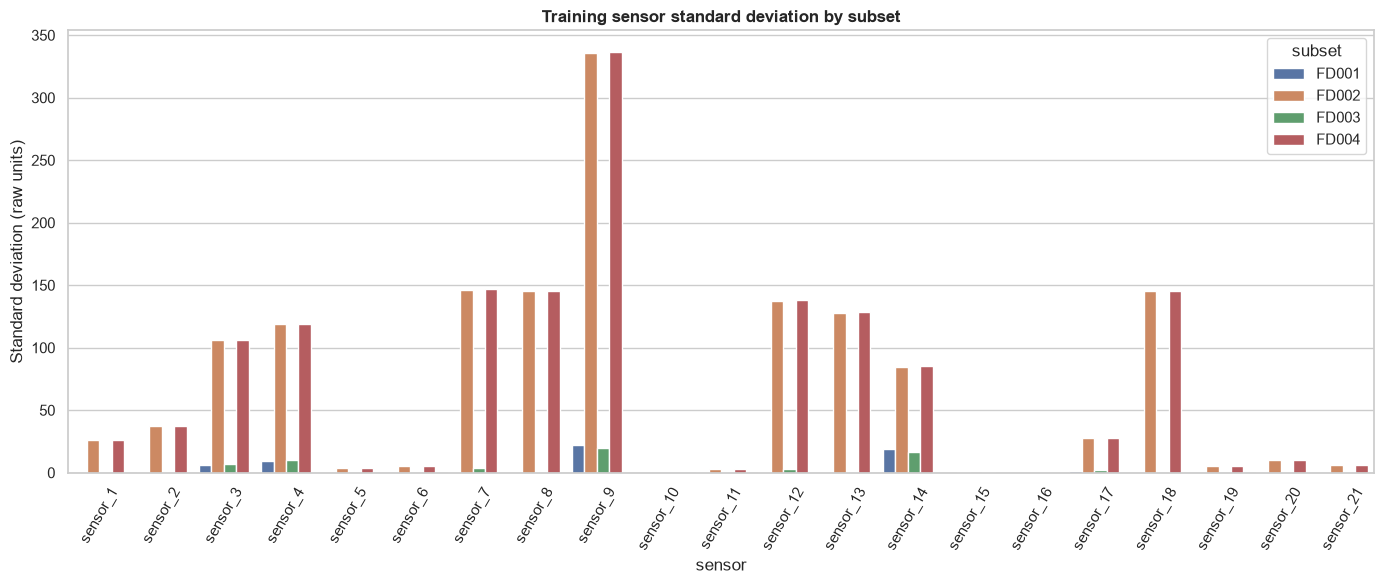

In [5]:
sensor_stats = {}
sensor_std_rows = []
for subset, parts in datasets.items():
    stats = parts["train"][SENSOR_COLS].agg(["mean", "std", "min", "max"]).T
    stats["subset"] = subset
    sensor_stats[subset] = stats
    for sensor, row in stats.iterrows():
        sensor_std_rows.append({"subset": subset, "sensor": sensor, "std": row["std"], "mean": row["mean"]})
sensor_std = pd.DataFrame(sensor_std_rows)
constant_table = sensor_std.pivot(index="sensor", columns="subset", values="std")
display(constant_table.round(5))

NEAR_CONSTANT_STD = 1e-8
near_constant = {
    subset: stats.index[stats["std"].fillna(0) <= NEAR_CONSTANT_STD].tolist()
    for subset, stats in sensor_stats.items()
}
print("Sensors with std <=", NEAR_CONSTANT_STD, "by subset:")
for subset, sensors in near_constant.items():
    print(f"  {subset}: {sensors if sensors else 'none'}")

fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(data=sensor_std, x="sensor", y="std", hue="subset", ax=ax)
ax.set_title("Training sensor standard deviation by subset")
ax.set_ylabel("Standard deviation (raw units)")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

## 4. FD001 detailed sensor analysis

FD001 is the simplest subset (one operating condition, one fault mode), so it is useful for establishing baseline data behavior. The following plots use the four most variable sensors in FD001 training data as an automatic, reproducible selection—not as a claim that they are the best model features.

FD001 sensors selected by training standard deviation: ['sensor_9', 'sensor_14', 'sensor_4', 'sensor_3']


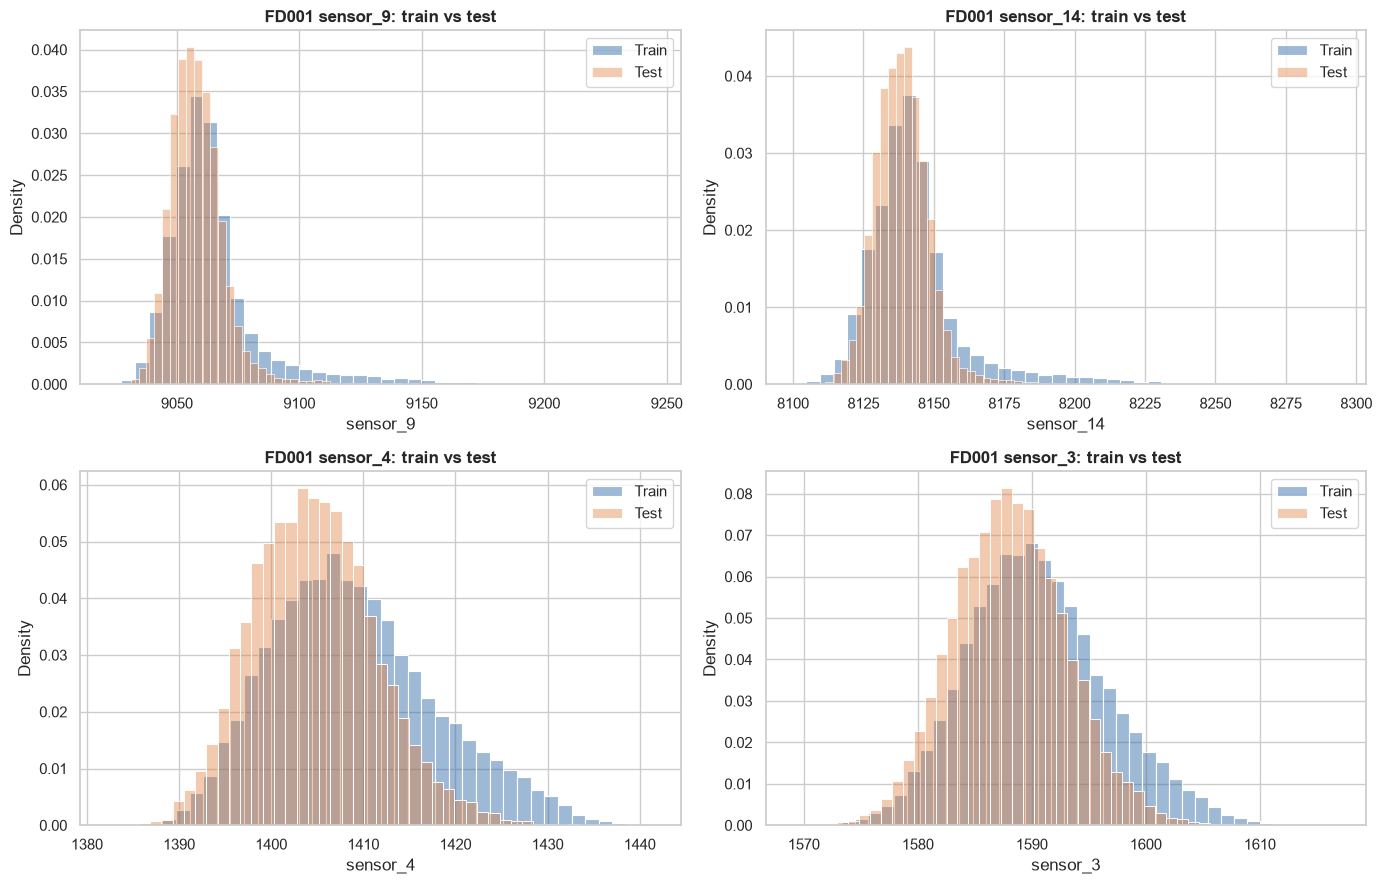

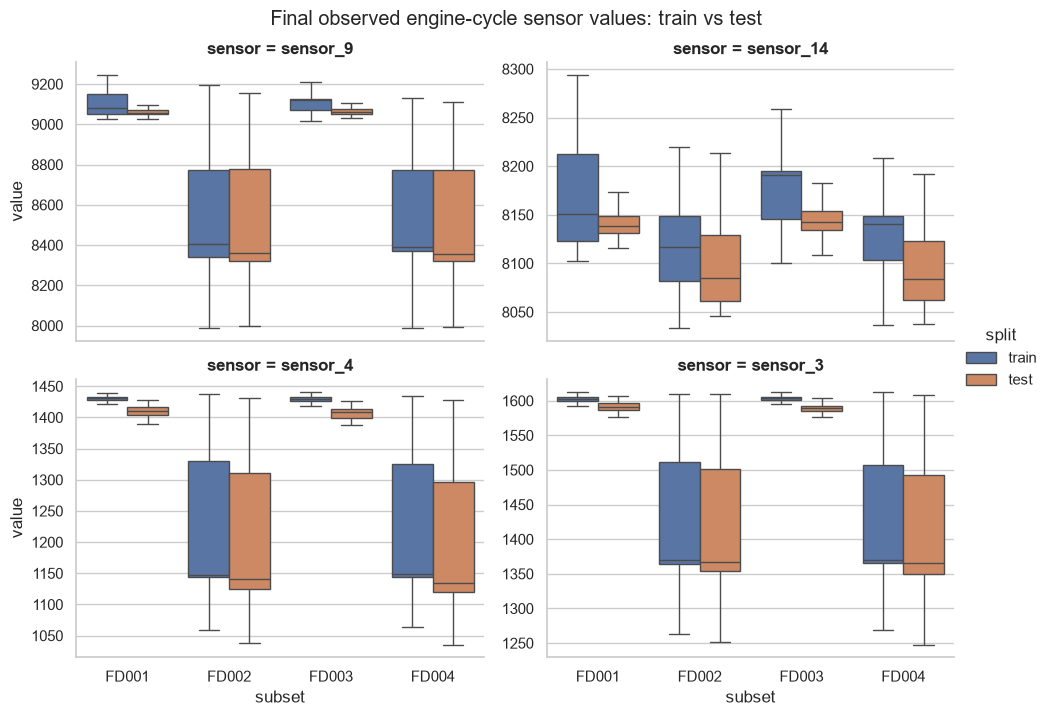

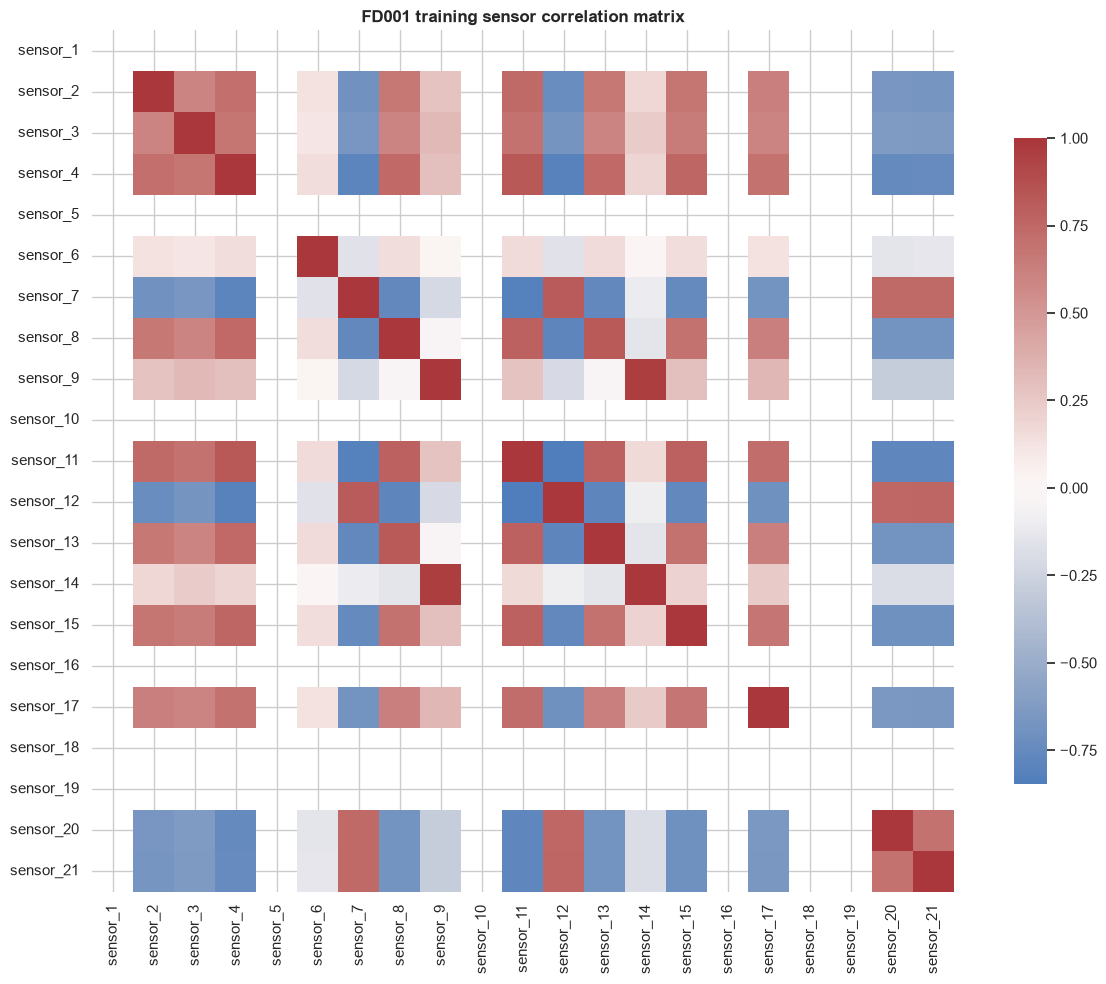

In [6]:
fd1_train = datasets["FD001"]["train"].copy()
fd1_test = datasets["FD001"]["test"].copy()
top_sensors_fd1 = fd1_train[SENSOR_COLS].std().sort_values(ascending=False).head(4).index.tolist()
print("FD001 sensors selected by training standard deviation:", top_sensors_fd1)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for sensor, ax in zip(top_sensors_fd1, axes.flat):
    sns.histplot(data=fd1_train, x=sensor, bins=40, stat="density", color="#2864a5", alpha=0.45, label="Train", ax=ax)
    sns.histplot(data=fd1_test, x=sensor, bins=40, stat="density", color="#e07b39", alpha=0.4, label="Test", ax=ax)
    ax.set_title(f"FD001 {sensor}: train vs test")
    ax.legend()
plt.tight_layout()
plt.show()

# Compare final observed sensor values per engine, rather than all cycle rows.
endpoint_sensors = []
for subset, parts in datasets.items():
    for split in ["train", "test"]:
        last = parts[split].sort_values(["unit", "cycle"]).groupby("unit", as_index=False).tail(1).copy()
        last["subset"] = subset
        last["split"] = split
        endpoint_sensors.append(last[["subset", "split", *top_sensors_fd1]])
endpoint_sensors = pd.concat(endpoint_sensors, ignore_index=True).melt(
    id_vars=["subset", "split"], var_name="sensor", value_name="value"
)
g = sns.catplot(data=endpoint_sensors, x="subset", y="value", hue="split", col="sensor",
                col_wrap=2, kind="box", sharey=False, showfliers=False, height=3.5, aspect=1.4)
g.fig.suptitle("Final observed engine-cycle sensor values: train vs test", y=1.02)
plt.show()

fd1_corr = fd1_train[SENSOR_COLS].corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(fd1_corr, cmap="vlag", center=0, square=True, ax=ax, cbar_kws={"shrink": 0.75})
ax.set_title("FD001 training sensor correlation matrix")
plt.tight_layout()
plt.show()

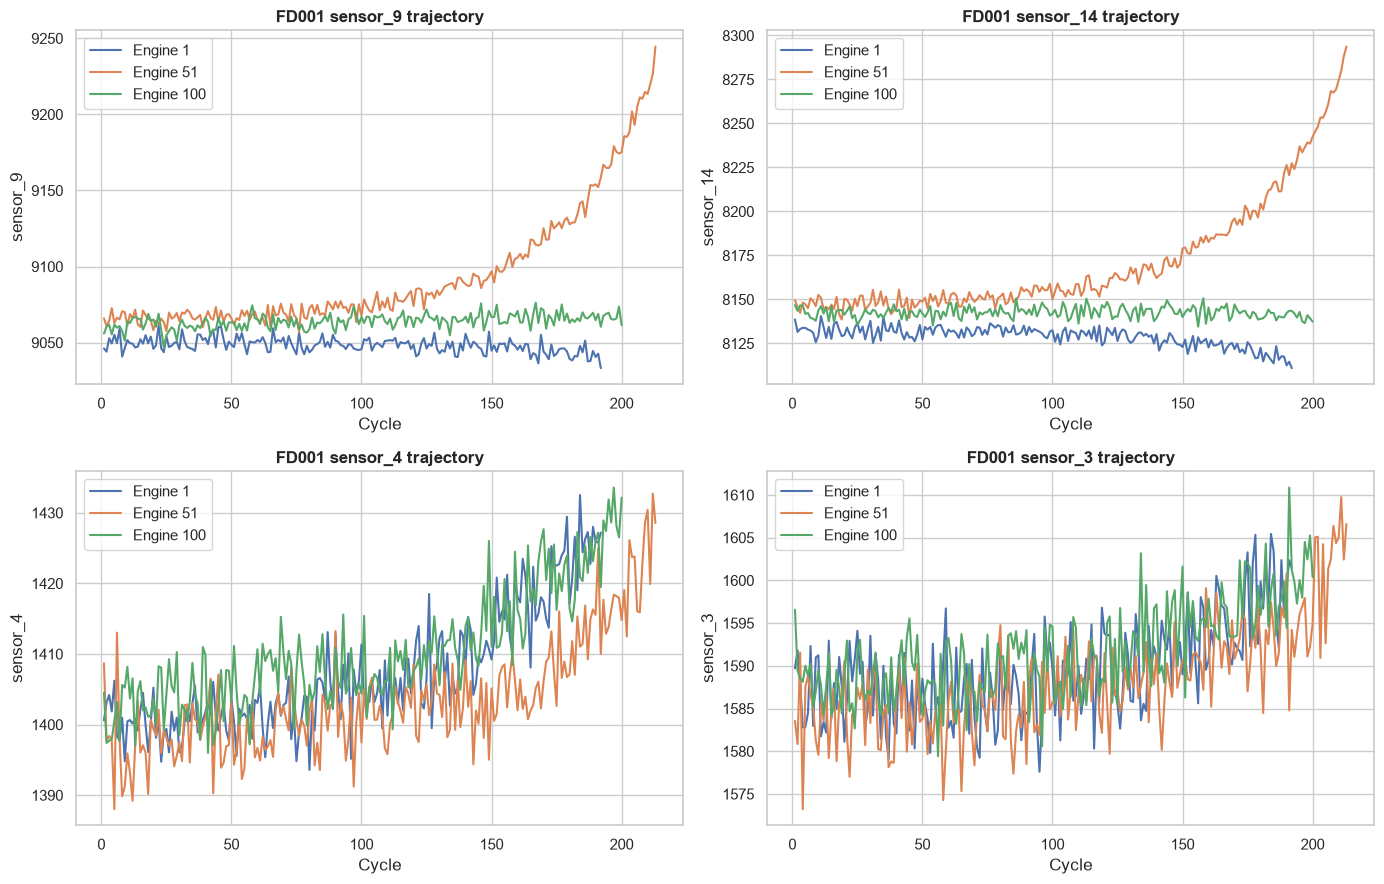

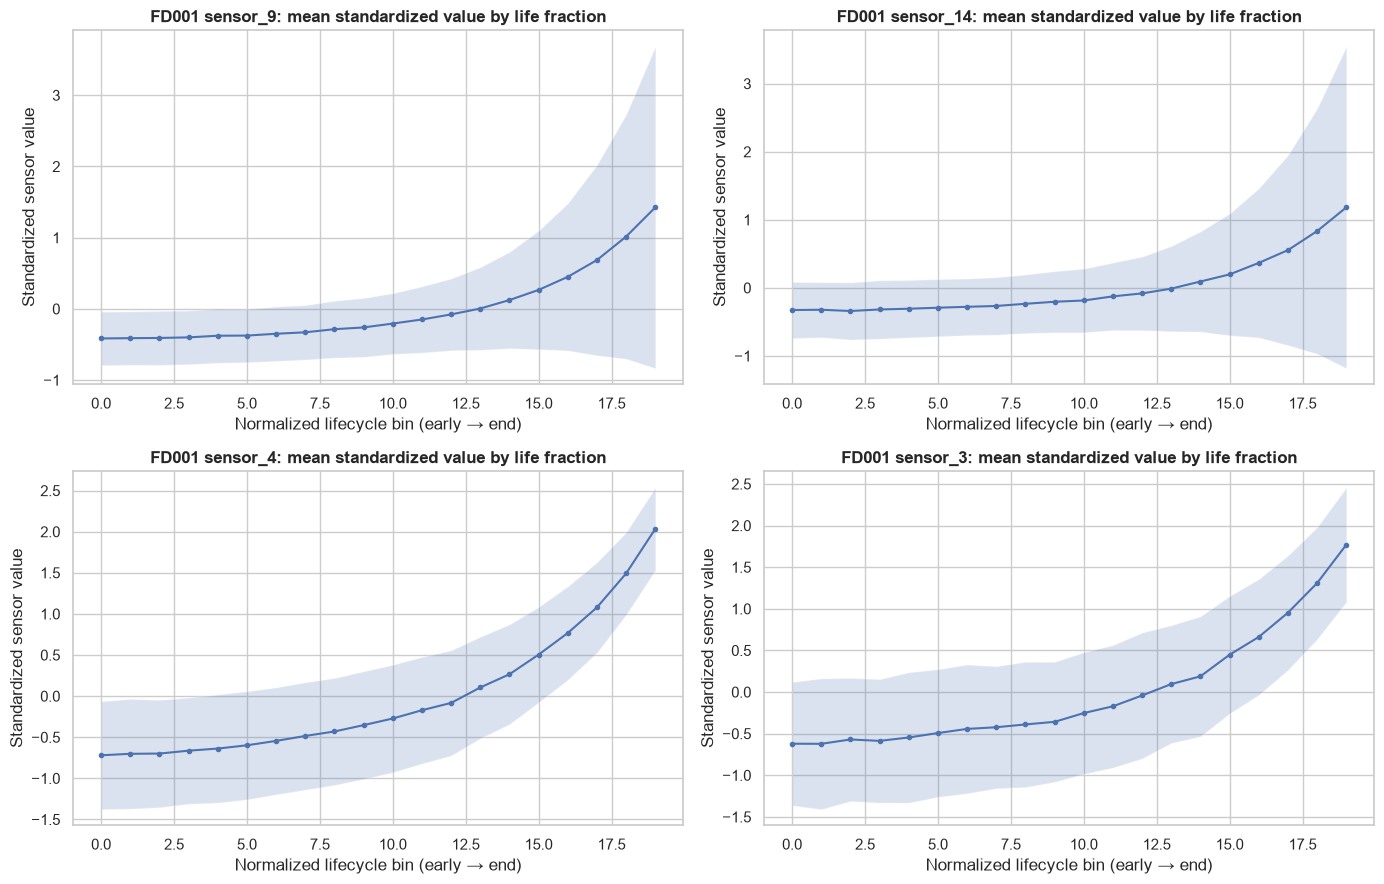

In [7]:
# Plot trajectories from early, middle, and late unit IDs in FD001.
fd1_units = sorted(fd1_train.unit.unique())
representative_units = sorted(set([fd1_units[0], fd1_units[len(fd1_units)//2], fd1_units[-1]]))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for sensor, ax in zip(top_sensors_fd1, axes.flat):
    for unit in representative_units:
        trajectory = fd1_train.loc[fd1_train.unit == unit].sort_values("cycle")
        ax.plot(trajectory.cycle, trajectory[sensor], linewidth=1.5, label=f"Engine {unit}")
    ax.set_title(f"FD001 {sensor} trajectory")
    ax.set_xlabel("Cycle")
    ax.set_ylabel(sensor)
    ax.legend()
plt.tight_layout()
plt.show()

# Align lifecycle progress to [0, 1] per engine and summarize standardized signals.
fd1_life = fd1_train.copy()
fd1_life["life_fraction"] = fd1_life["cycle"] / fd1_life.groupby("unit")["cycle"].transform("max")
fd1_life["life_bin"] = pd.cut(fd1_life["life_fraction"], bins=np.linspace(0, 1, 21), include_lowest=True)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for sensor, ax in zip(top_sensors_fd1, axes.flat):
    mu = fd1_train[sensor].mean()
    sigma = fd1_train[sensor].std() or 1
    fd1_life[f"{sensor}_z"] = (fd1_life[sensor] - mu) / sigma
    trend = fd1_life.groupby("life_bin", observed=False)[f"{sensor}_z"].agg(["mean", "std"]).reset_index()
    x = np.arange(len(trend))
    ax.plot(x, trend["mean"], marker="o", markersize=3)
    ax.fill_between(x, trend["mean"] - trend["std"], trend["mean"] + trend["std"], alpha=0.2)
    ax.set_title(f"FD001 {sensor}: mean standardized value by life fraction")
    ax.set_xlabel("Normalized lifecycle bin (early → end)")
    ax.set_ylabel("Standardized sensor value")
plt.tight_layout()
plt.show()

## 5. RUL targets and train/test endpoint analysis

For each training engine, cycle-level RUL is constructed as `last training cycle - current cycle`. For each test engine, the supplied RUL is a label for the engine’s **last observed test cycle**, in ascending unit-ID order. Test RUL does not label every cycle in the test trajectory.

,train_min,train_median,train_max,test_min,test_median,test_max
subset,,,,,,
FD001,0,103.0,361,7,86.0,145
FD002,0,103.0,377,6,80.0,194
FD003,0,123.0,524,6,77.5,145
FD004,0,122.0,542,6,88.0,195


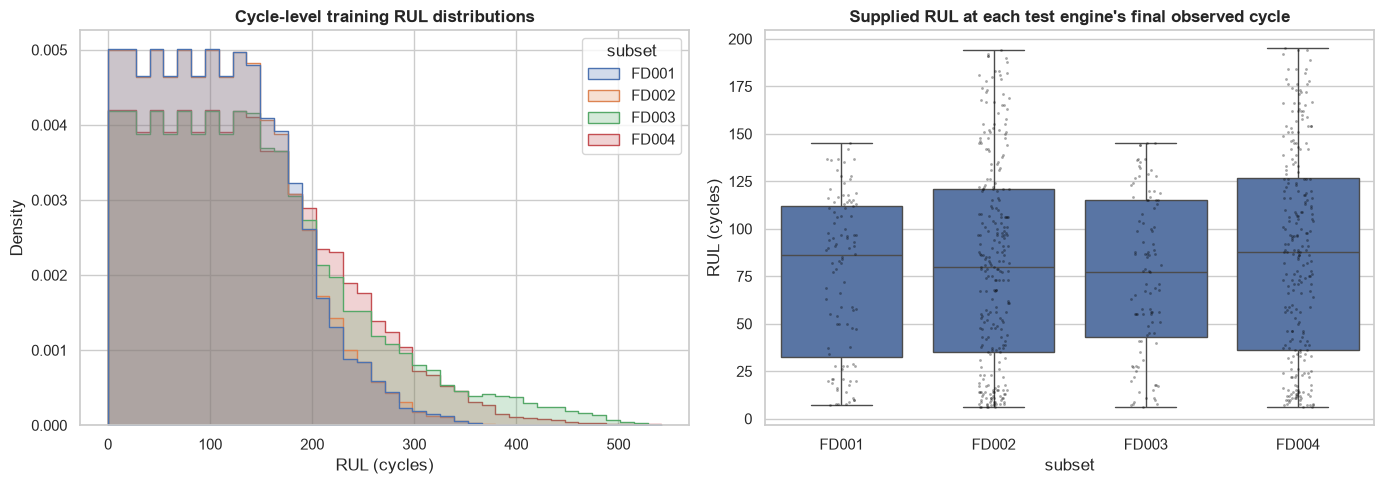

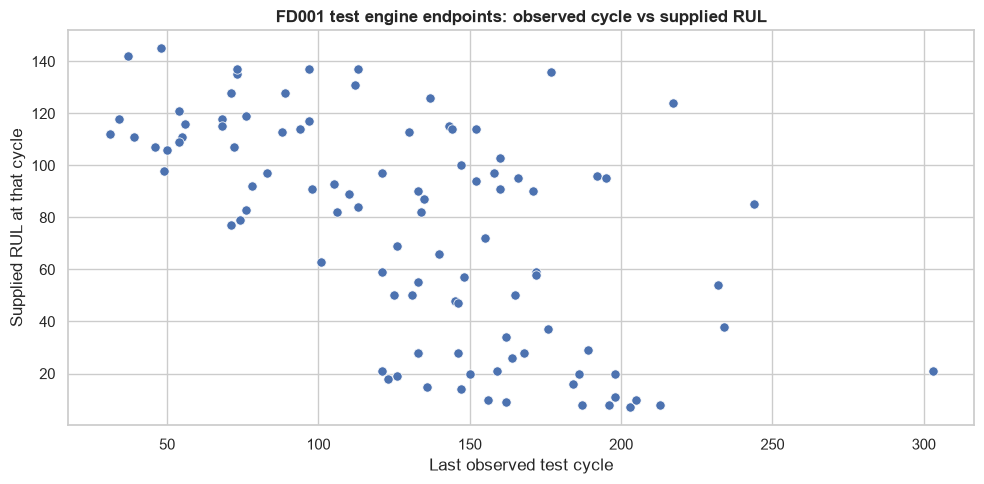

In [8]:
rul_frames = []
endpoint_frames = []
for subset, parts in datasets.items():
    train = parts["train"].copy()
    train["rul"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
    train["subset"] = subset
    rul_frames.append(train[["subset", "unit", "cycle", "rul"]])

    test = parts["test"]
    last_rows = test.sort_values(["unit", "cycle"]).groupby("unit", as_index=False).tail(1).sort_values("unit").copy()
    last_rows["rul"] = parts["rul"].to_numpy()
    last_rows["subset"] = subset
    endpoint_frames.append(last_rows[["subset", "unit", "cycle", "rul"]])

train_rul_all = pd.concat(rul_frames, ignore_index=True)
test_endpoints = pd.concat(endpoint_frames, ignore_index=True)
rul_summary = pd.concat([
    train_rul_all.groupby("subset").rul.agg(train_min="min", train_median="median", train_max="max"),
    test_endpoints.groupby("subset").rul.agg(test_min="min", test_median="median", test_max="max"),
], axis=1)
display(rul_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=train_rul_all, x="rul", hue="subset", bins=40, element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Cycle-level training RUL distributions")
axes[0].set_xlabel("RUL (cycles)")
sns.boxplot(data=test_endpoints, x="subset", y="rul", ax=axes[1])
sns.stripplot(data=test_endpoints, x="subset", y="rul", color="black", alpha=0.35, size=2, ax=axes[1])
axes[1].set_title("Supplied RUL at each test engine's final observed cycle")
axes[1].set_ylabel("RUL (cycles)")
plt.tight_layout()
plt.show()

fd1_endpoints = test_endpoints.query("subset == 'FD001'")
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=fd1_endpoints, x="cycle", y="rul", s=45, ax=ax)
ax.set_title("FD001 test engine endpoints: observed cycle vs supplied RUL")
ax.set_xlabel("Last observed test cycle")
ax.set_ylabel("Supplied RUL at that cycle")
plt.tight_layout()
plt.show()

## 6. Comparable EDA across FD001–FD004

This section compares sensor spread and operating settings across subsets. A broad distribution may reflect multiple operating regimes, fault modes, engine-to-engine differences, or degradation. These pooled plots are descriptive; they should not be read as causal degradation comparisons.

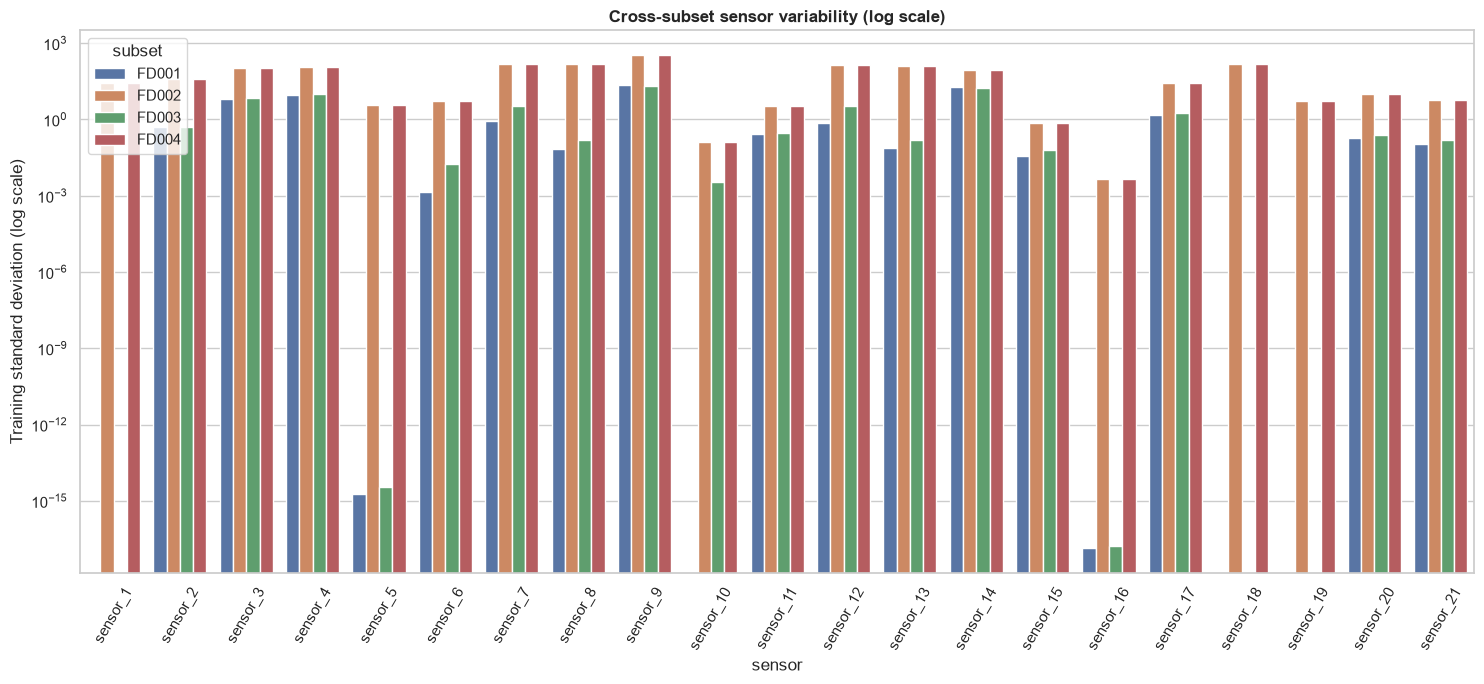

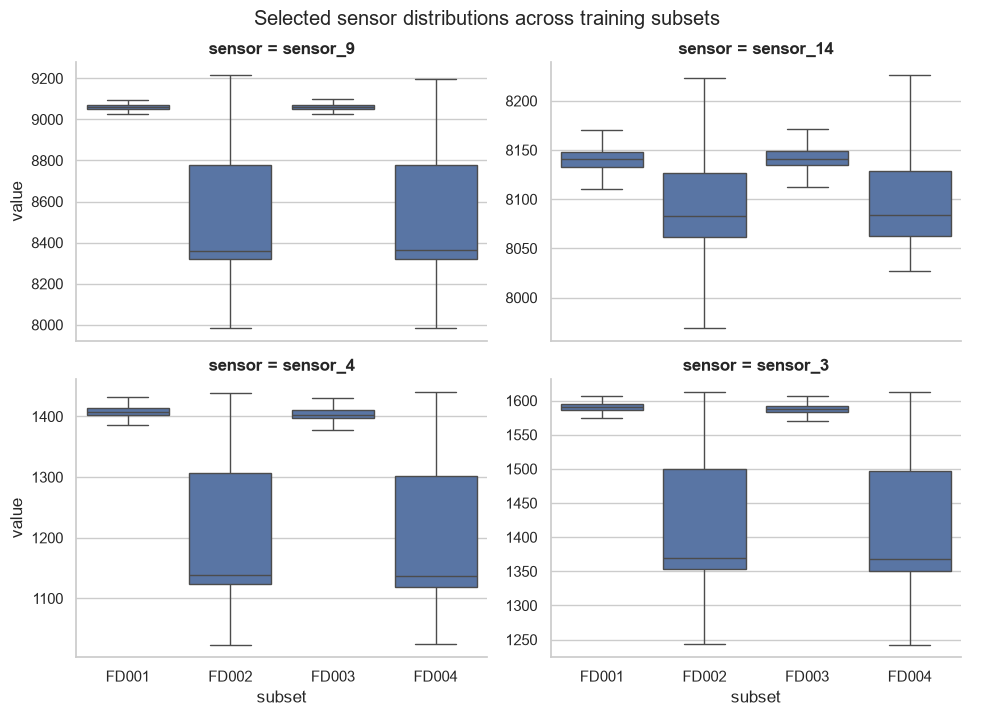

,operating_conditions_from_readme,fault_modes_from_readme
subset,,
FD001,1,1
FD002,6,1
FD003,1,2
FD004,6,2


In [9]:
# Sensor standard deviations shown on a log scale to reveal small and large spreads.
fig, ax = plt.subplots(figsize=(15, 7))
sns.barplot(data=sensor_std, x="sensor", y="std", hue="subset", ax=ax)
ax.set_yscale("log")
ax.set_title("Cross-subset sensor variability (log scale)")
ax.set_ylabel("Training standard deviation (log scale)")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

# Compare representative sensor distributions; selected using FD001 variance.
sensor_long = pd.concat([
    parts["train"].assign(subset=subset)[["subset", *top_sensors_fd1]]
    for subset, parts in datasets.items()
], ignore_index=True).melt(id_vars="subset", var_name="sensor", value_name="value")
g = sns.catplot(data=sensor_long, x="subset", y="value", col="sensor", col_wrap=2,
                kind="box", sharey=False, showfliers=False, height=3.5, aspect=1.4)
g.fig.suptitle("Selected sensor distributions across training subsets", y=1.02)
plt.show()

subset_characteristics = pd.DataFrame({
    "operating_conditions_from_readme": [1, 6, 1, 6],
    "fault_modes_from_readme": [1, 1, 2, 2],
}, index=SUBSETS)
subset_characteristics.index.name = "subset"
display(subset_characteristics)

## 7. Findings and implications for the next step

The summary below is computed from the files loaded in this run. It is a compact evidence log, not a model evaluation. Use it to decide which sensors and operating-condition handling to investigate next; do not select features solely from pooled raw correlations.

In [10]:
findings = []
findings.append(f"Loaded all four subsets from {DATA_DIR.resolve()} with {len(COLS)} columns per row.")
problems = quality[(quality[["missing_cells", "nonfinite_cells", "duplicate_unit_cycle", "non_increasing_cycles"]] > 0).any(axis=1)]
findings.append("Quality checks: no flagged missing/nonfinite values, duplicate keys, or cycle-order violations." if problems.empty
                else f"Quality checks flagged {len(problems)} split(s); inspect the quality table before proceeding.")
findings.append(f"FD001 most-variable sensors by training standard deviation: {', '.join(top_sensors_fd1)}.")
findings.append("FD002 and FD004 contain six operating conditions according to the dataset README; condition-aware normalization should be evaluated before interpreting pooled sensor shifts.")
if datasets["FD004"]["train"].unit.nunique() == 249 and datasets["FD004"]["test"].unit.nunique() == 248:
    findings.append("FD004 README count discrepancy: it states 248 train / 249 test engines, while the provided files contain 249 train / 248 test; the file counts are used and test/RUL counts align.")
findings.append("Training RUL labels are derivable from each engine's final training cycle; test RUL labels apply only to each engine's final observed test row.")
findings.append("Next: split by engine ID, fit any preprocessing on training engines only, then build causal features and evaluate an RUL baseline with RMSE/MAE and the NASA asymmetric score.")
for item in findings:
    print("•", item)

print("\nUseful analysis tables: quality, inventory, sensor_stats, train_rul_all, test_endpoints.")

• Loaded all four subsets from C:\Users\devan\Downloads\casestudy1sol\CMAPSSData with 26 columns per row.
• Quality checks: no flagged missing/nonfinite values, duplicate keys, or cycle-order violations.
• FD001 most-variable sensors by training standard deviation: sensor_9, sensor_14, sensor_4, sensor_3.
• FD002 and FD004 contain six operating conditions according to the dataset README; condition-aware normalization should be evaluated before interpreting pooled sensor shifts.
• FD004 README count discrepancy: it states 248 train / 249 test engines, while the provided files contain 249 train / 248 test; the file counts are used and test/RUL counts align.
• Training RUL labels are derivable from each engine's final training cycle; test RUL labels apply only to each engine's final observed test row.
• Next: split by engine ID, fit any preprocessing on training engines only, then build causal features and evaluate an RUL baseline with RMSE/MAE and the NASA asymmetric score.

Useful analy

## 8. Data readiness and approach-selection diagnostics

This section goes beyond pooled plots to support feature and method choices before model training. It creates a deterministic, lifetime-stratified 80/20 development/validation split **by engine**, checks split integrity and life-range coverage, measures sensor trend consistency within each engine, and screens whether rounded operating-setting groups explain sensor variance. Sensor ranking is a hypothesis-generation tool—not model feature importance or a performance result.

The supplied C-MAPSS review highlights sensor noise, operating-condition effects, and multiple failure modes; the 2023 paper motivates rolling-window statistics, PCA, and cross-validation aggregated feature importance (AFICv). Preparation modules below make alternatives runnable from this notebook while leaving model fitting for the next stage.

**References:** Ramasso & Saxena (2014), *Review and Analysis of Algorithmic Approaches Developed for Prognostics on CMAPSS Dataset*; Alomari et al. (2023), *Advancing aircraft engine RUL predictions: an interpretable integrated approach of feature engineering and aggregated feature importance*, Scientific Reports 13, 13466, https://doi.org/10.1038/s41598-023-40315-1.

,subset,split,rows,engines,missing_cells,nonfinite_cells,duplicate_unit_cycle,non_increasing_cycles_sorted,out_of_order_cycles_in_file,cycle_gaps,invalid_unit_or_cycle,missing_unit_ids_in_range,cycle_min,cycle_max,unit_min,unit_max
0,FD001,train,20631,100,0,0,0,0,0,0,0,0,1,362,1,100
1,FD001,test,13096,100,0,0,0,0,0,0,0,0,1,303,1,100
2,FD002,train,53759,260,0,0,0,0,0,0,0,0,1,378,1,260
3,FD002,test,33991,259,0,0,0,0,0,0,0,0,1,367,1,259
4,FD003,train,24720,100,0,0,0,0,0,0,0,0,1,525,1,100
5,FD003,test,16596,100,0,0,0,0,0,0,0,0,1,475,1,100
6,FD004,train,61249,249,0,0,0,0,0,0,0,0,1,543,1,249
7,FD004,test,41214,248,0,0,0,0,0,0,0,0,1,486,1,248


,subset,split,engines,rows,rows_pct,median_engine_cycles,min_engine_cycles,max_engine_cycles,median_cycle_level_rul
0,FD001,development,80,16538,80.16,199.5,135,362,103.0
1,FD001,validation,20,4093,19.84,194.5,128,283,102.0
2,FD002,development,208,43162,80.29,200.0,128,378,103.0
3,FD002,validation,52,10597,19.71,197.5,129,343,101.0
4,FD003,development,80,19553,79.10,221.5,145,525,122.0
5,FD003,validation,20,5167,20.90,216.5,158,494,129.0
6,FD004,development,199,49247,80.40,239.0,128,543,123.0
7,FD004,validation,50,12002,19.60,228.5,131,375,120.0


Split integrity passed: no engine overlap, no dropped training rows, RUL labels consistent.


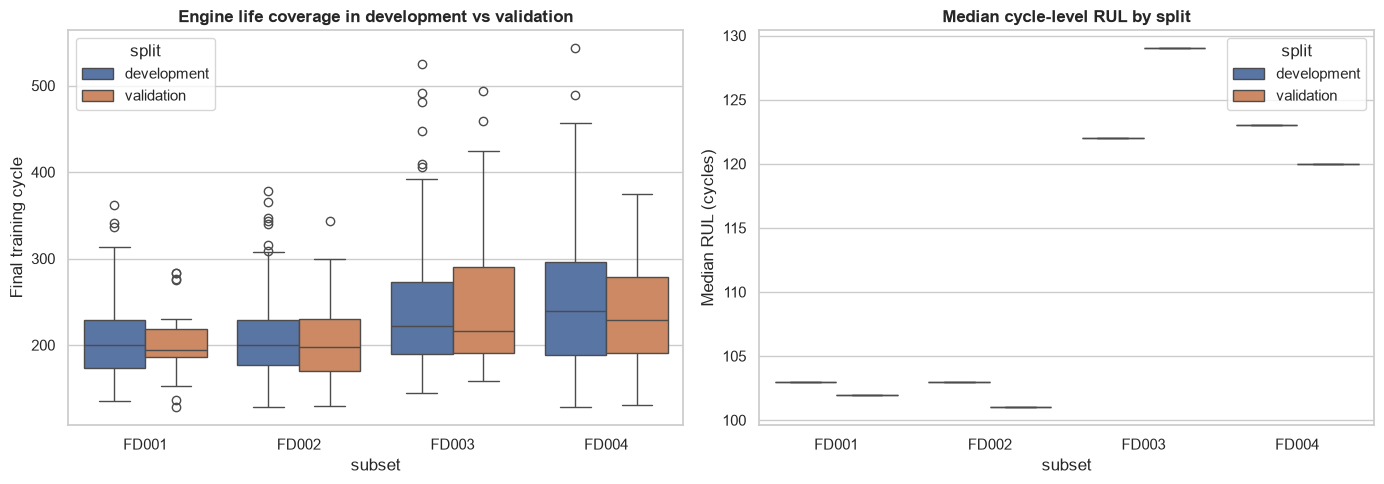

In [11]:
import sys
sys.path.insert(0, str(DATA_DIR.resolve().parent))

from cmapss_analysis import build_development_splits
from cmapss_data import add_training_rul, load_subset

# Reload through shared project utilities so notebook checks and later scripts agree.
shared_data = {subset: load_subset(DATA_DIR, subset) for subset in SUBSETS}
prepared, split_profile = build_development_splits(
    shared_data, validation_fraction=0.20, random_state=42
)

extended_quality = pd.concat(
    [parts["quality"] for parts in shared_data.values()], ignore_index=True
)
display(extended_quality)
display(split_profile.round(2))

engine_profiles = pd.concat(
    [parts["engine_split"].assign(subset=subset)
     for subset, parts in prepared.items()],
    ignore_index=True,
)
for subset, parts in prepared.items():
    development_ids = set(parts["development"].unit.unique())
    validation_ids = set(parts["validation"].unit.unique())
    assert development_ids.isdisjoint(validation_ids)
    assert len(parts["development"]) + len(parts["validation"]) == len(parts["train_labeled"])
    assert parts["train_labeled"].groupby("unit").rul_uncapped.max().eq(
        parts["train_labeled"].groupby("unit").cycle.max()
        - parts["train_labeled"].groupby("unit").cycle.min()
    ).all()
print("Split integrity passed: no engine overlap, no dropped training rows, RUL labels consistent.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=engine_profiles, x="subset", y="last_cycle", hue="split", ax=axes[0])
axes[0].set_title("Engine life coverage in development vs validation")
axes[0].set_ylabel("Final training cycle")
sns.boxplot(data=split_profile, x="subset", y="median_cycle_level_rul", hue="split", ax=axes[1])
axes[1].set_title("Median cycle-level RUL by split")
axes[1].set_ylabel("Median RUL (cycles)")
plt.tight_layout()
plt.show()

### 8.1 Sensor evidence: trend, setting effects, and split stability

For each training sensor, the trend screen computes Spearman association with cycle **inside each development engine**, then summarizes median absolute trend strength and whether direction is consistent across engines. This avoids letting long engines dominate a pooled row-level correlation. The setting screen estimates the share of sensor variance associated with settings rounded to one decimal; these bins are only a diagnostic (they are not asserted to be the official six condition labels). Engine-level mean shifts compare development and validation. Condition-adjusted correlations remove setting-group means before screening redundant sensors. Use all measures as evidence, not as an automatic feature-selection rule.

Per-engine development sensor trend evidence (top 8 per subset):

FD001: rounded setting groups=1


,sensor,engines_with_trend,median_spearman_sensor_vs_cycle,median_abs_engine_spearman,direction_consistency,positive_trend_fraction,negative_trend_fraction,engines_abs_rho_ge_0_5,median_late_minus_early_in_engine_sd,std,unique_values,trend_screen_score
10,sensor_11,80,0.820,0.820,1.0,1.0,0.0,1.000,2.295,0.268,156,0.820
11,sensor_12,80,-0.812,0.812,1.0,0.0,1.0,1.000,-2.282,0.745,419,0.812
3,sensor_4,80,0.787,0.787,1.0,1.0,0.0,1.000,2.280,9.006,3884,0.787
12,sensor_13,80,0.786,0.786,1.0,1.0,0.0,0.850,2.210,0.073,56,0.786
6,sensor_7,80,-0.779,0.779,1.0,0.0,1.0,1.000,-2.174,0.892,506,0.779
7,sensor_8,80,0.771,0.771,1.0,1.0,0.0,0.862,2.179,0.072,51,0.771
20,sensor_21,80,-0.726,0.726,1.0,0.0,1.0,1.000,-2.064,0.108,4518,0.726
14,sensor_15,80,0.722,0.722,1.0,1.0,0.0,1.000,2.070,0.038,1869,0.722


Largest setting-associated variance shares:


,sensor,setting_group_variance_share,overall_std
0,sensor_1,0.0,0.000
11,sensor_12,0.0,0.745
19,sensor_20,0.0,0.181
18,sensor_19,0.0,0.000
17,sensor_18,0.0,0.000
16,sensor_17,0.0,1.546


Development/validation setting coverage distance:


...

,sensor,setting_group_variance_share,overall_std
0,sensor_1,1.0,26.421
17,sensor_18,1.0,145.565
4,sensor_5,1.0,3.621
18,sensor_19,1.0,5.374
7,sensor_8,1.0,145.440
12,sensor_13,1.0,128.312


Development/validation setting coverage distance:


,comparison,total_variation_distance
0,development vs validation,0.004
1,development vs official test,0.007


Largest engine-mean standardized shifts (diagnostic only):


,sensor,development_engine_mean,validation_engine_mean,standardized_mean_difference
13,sensor_14,8067.325,8065.986,-0.139
18,sensor_19,97.746,97.766,0.067
12,sensor_13,2334.292,2334.765,0.064
17,sensor_18,2228.470,2228.995,0.063
7,sensor_8,2228.541,2229.048,0.061


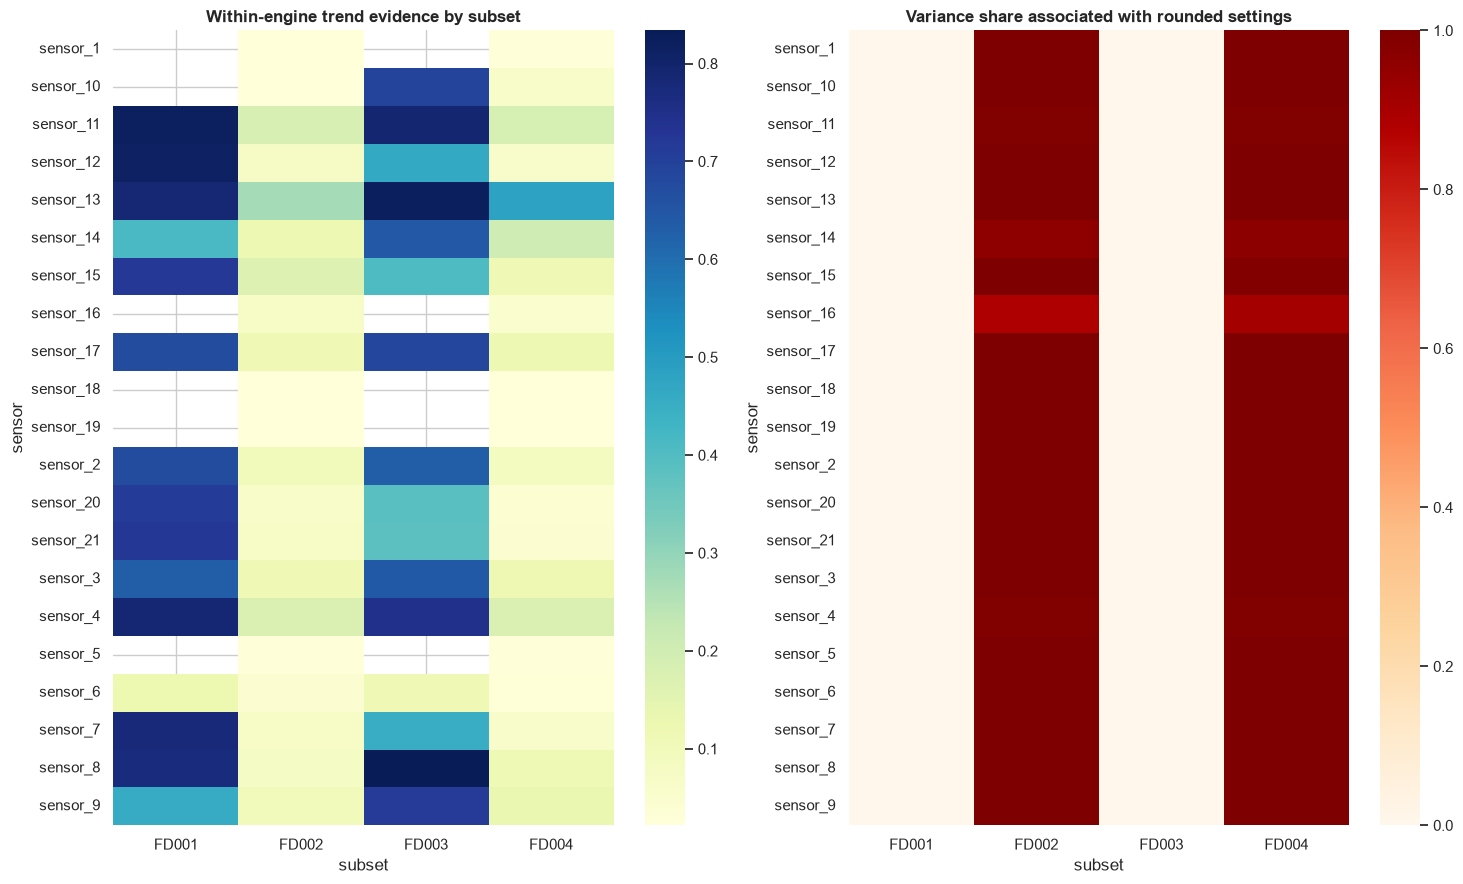

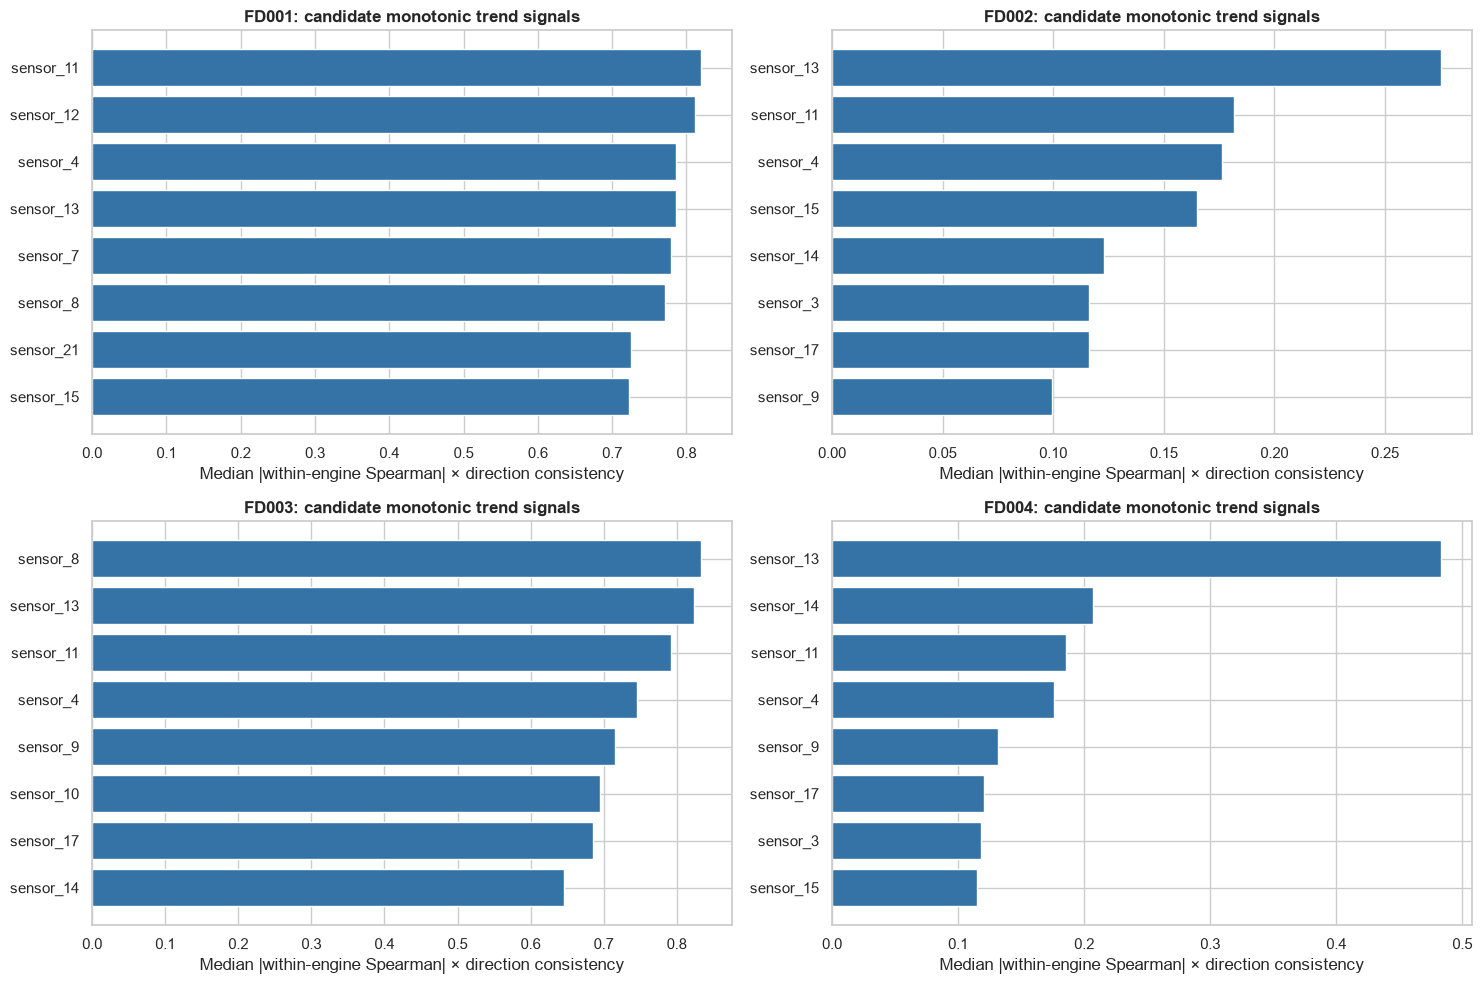

FD001: condition-adjusted sensor pairs with |Spearman rho| >= 0.95: 0


,sensor_a,sensor_b,spearman_rho


FD002: condition-adjusted sensor pairs with |Spearman rho| >= 0.95: 0


,sensor_a,sensor_b,spearman_rho


FD003: condition-adjusted sensor pairs with |Spearman rho| >= 0.95: 1


,sensor_a,sensor_b,spearman_rho
0,sensor_7,sensor_12,0.951


FD004: condition-adjusted sensor pairs with |Spearman rho| >= 0.95: 1


,sensor_a,sensor_b,spearman_rho
0,sensor_8,sensor_13,0.956


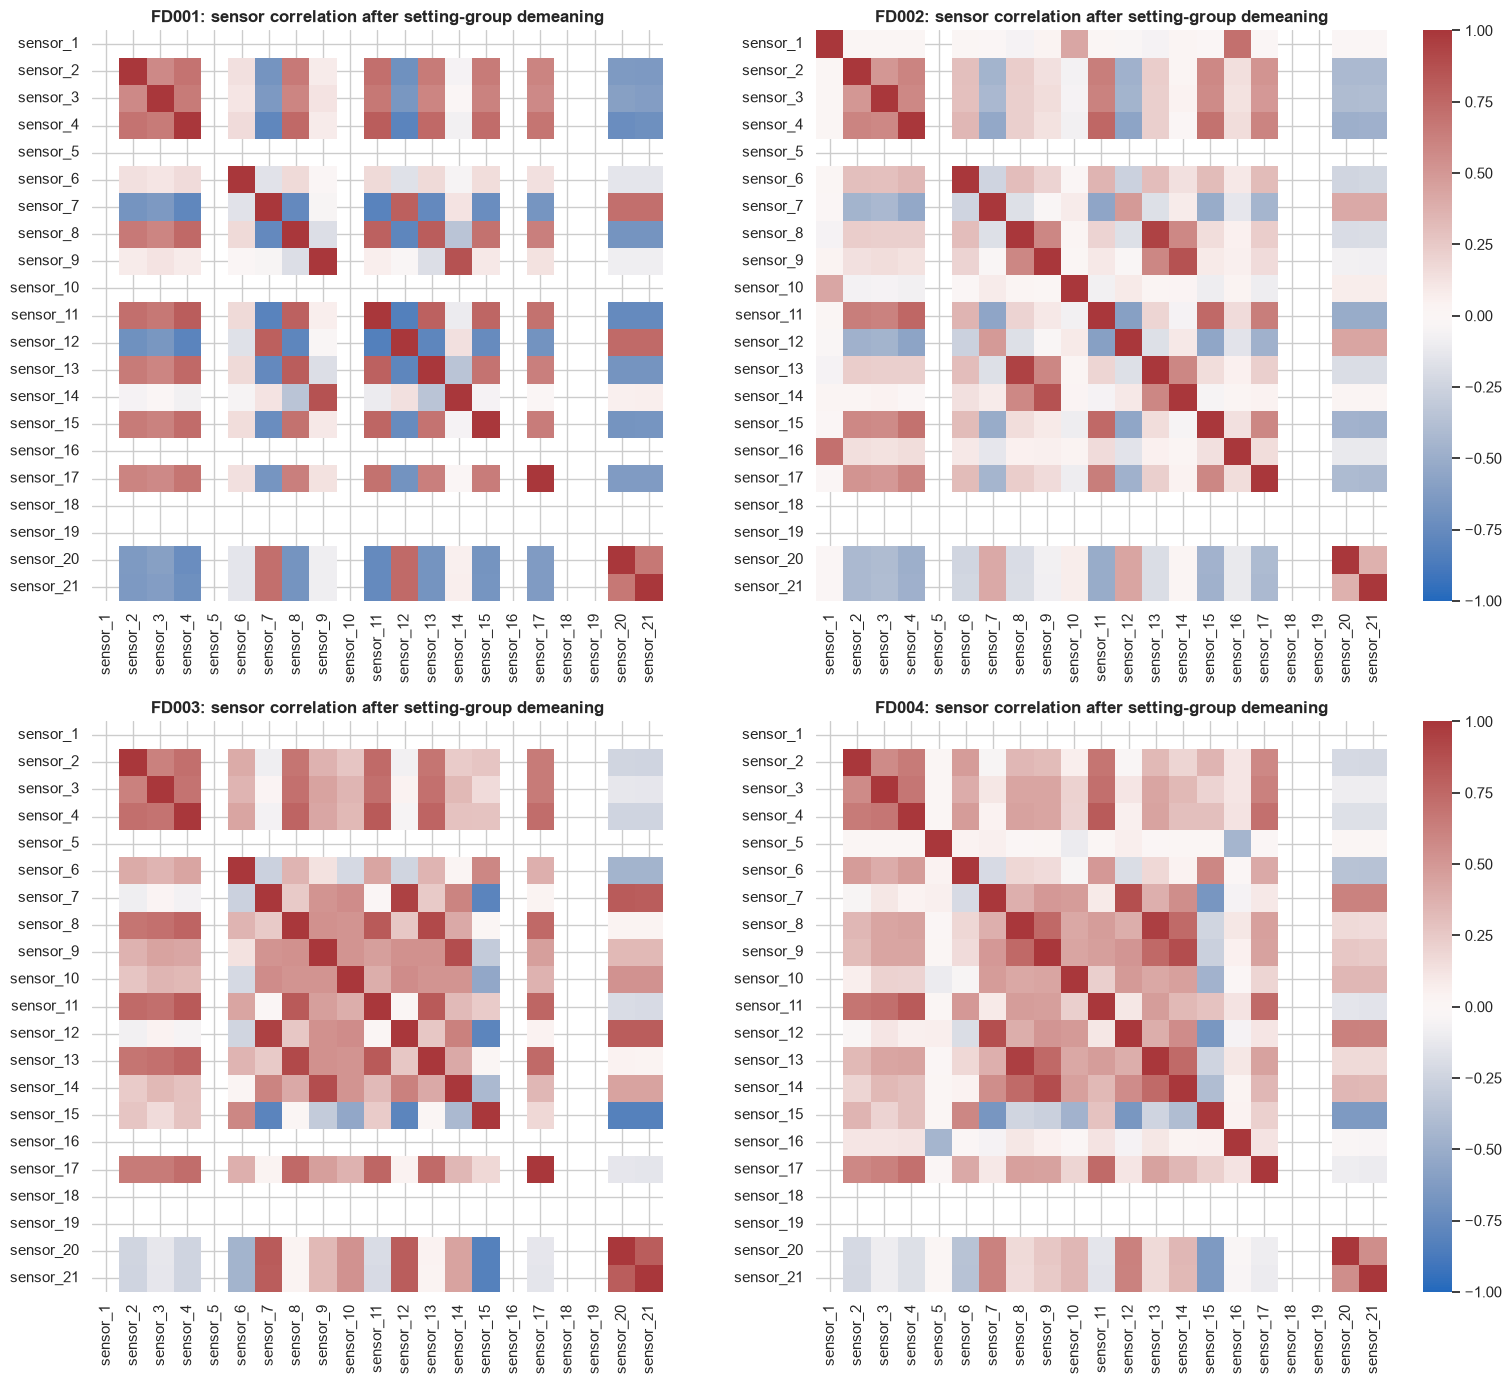

In [12]:
from cmapss_analysis import (
    engine_mean_shift,
    sensor_trend_evidence,
    setting_distribution_shift,
    setting_effect_evidence,
)

trend_tables = {}
setting_tables = {}
split_shift_tables = {}
setting_coverage_tables = {}
combined_sensor_evidence = []
for subset, parts in prepared.items():
    development = parts["development"]
    trends = sensor_trend_evidence(development)
    setting_effects, setting_groups = setting_effect_evidence(development)
    shifts = engine_mean_shift(development, parts["validation"])
    condition_mix, condition_shift = setting_distribution_shift(
        development, parts["validation"], parts["test"]
    )
    trend_tables[subset] = trends
    setting_tables[subset] = setting_effects
    split_shift_tables[subset] = shifts
    setting_coverage_tables[subset] = (condition_mix, condition_shift)
    combined_sensor_evidence.append(
        trends.merge(setting_effects, on="sensor", suffixes=("", "_setting"))
        .merge(shifts[["sensor", "standardized_mean_difference"]], on="sensor")
        .assign(subset=subset)
    )

sensor_evidence = pd.concat(combined_sensor_evidence, ignore_index=True)
print("Per-engine development sensor trend evidence (top 8 per subset):")
for subset in SUBSETS:
    print(f"\n{subset}: rounded setting groups={len(setting_coverage_tables[subset][0])}")
    display(trend_tables[subset].head(8).round(3))
    print("Largest setting-associated variance shares:")
    display(setting_tables[subset].head(6).round(3))
    print("Development/validation setting coverage distance:")
    display(setting_coverage_tables[subset][1].round(3))
    print("Largest engine-mean standardized shifts (diagnostic only):")
    display(split_shift_tables[subset].head(5).round(3))

trend_heat = sensor_evidence.pivot(
    index="sensor", columns="subset", values="trend_screen_score"
)
setting_heat = sensor_evidence.pivot(
    index="sensor", columns="subset", values="setting_group_variance_share"
)
fig, axes = plt.subplots(1, 2, figsize=(15, 9))
sns.heatmap(trend_heat, cmap="YlGnBu", annot=False, ax=axes[0])
axes[0].set_title("Within-engine trend evidence by subset")
sns.heatmap(setting_heat, cmap="OrRd", annot=False, vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Variance share associated with rounded settings")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for subset, ax in zip(SUBSETS, axes.flat):
    top = trend_tables[subset].head(8).sort_values("trend_screen_score")
    ax.barh(top.sensor, top.trend_screen_score, color="#3572A5")
    ax.set_title(f"{subset}: candidate monotonic trend signals")
    ax.set_xlabel("Median |within-engine Spearman| × direction consistency")
plt.tight_layout()
plt.show()

from cmapss_analysis import condition_adjusted_sensor_correlations, high_correlation_pairs
correlation_matrices = {}
for subset, parts in prepared.items():
    corr = condition_adjusted_sensor_correlations(parts["development"])
    correlation_matrices[subset] = corr
    pairs = high_correlation_pairs(corr, threshold=0.95)
    print(f"{subset}: condition-adjusted sensor pairs with |Spearman rho| >= 0.95: {len(pairs)}")
    display(pairs.head(10).round(3))

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for subset, ax in zip(SUBSETS, axes.flat):
    sns.heatmap(correlation_matrices[subset], cmap="vlag", center=0, vmin=-1, vmax=1,
                square=True, ax=ax, cbar=(subset in ("FD002", "FD004")))
    ax.set_title(f"{subset}: sensor correlation after setting-group demeaning")
plt.tight_layout()
plt.show()

### 8.2 Candidate preparation tracks and current decisions

| Track | Data preparation now | Model decision later |
|---|---|---|
| Engineered regression (required baseline) | Raw sensor/settings plus causal rolling mean, spread, delta, and slope at short and medium windows. | Compare tree regression and MLP; ablate raw-only vs rolling features and uncapped vs capped RUL. |
| AFICv / PCA (research-paper option) | Preserve feature names and development/validation boundaries. | Fit importance aggregation/PCA only inside engine-grouped training folds; retain AFICv's 70% rule as an experiment, not a fixed truth. |
| Sequence model (benchmark) | Build trailing, fixed-length windows independently per engine. | Test a small 1D-CNN/GRU only if it beats the engineered baseline on held-out engines. |
| Autoencoder / TinyML (optional extension) | Prepare early-life reference windows from development engines only. | Evaluate novelty/health signal separately; quantize only after offline utility and resource need are demonstrated. |

C-MAPSS records are cycle-level telemetry, not high-frequency vibration waveforms, so FFT/bearing-frequency features from your pump work are not directly suitable. Life-fraction plots are descriptive only and must not become inference features. Start with uncapped RUL, then compare any cap as a validation-only ablation; do not adopt a benchmark cap without evidence. For FD001/FD003, remove constant sensors in subset-specific experiments; for cross-subset comparisons, keep a consistent schema and record which columns are constant. No model is trained in this notebook.

### Decision log

1. **Split protocol:** hold out 20% of engines within each subset, stratified by training-trajectory length; never split rows from the same engine across development and validation. The official test/RUL pairs stay reserved for final evaluation.
2. **First model track:** start with interpretable raw + causal rolling features and a tree regressor; compare raw-only/rolling features and uncapped/capped target variants using engine-grouped validation.
3. **Operating conditions:** prioritize condition-aware feature handling on FD002/FD004 because sensor variance is strongly associated with settings; evaluate the adjustment rather than assuming a particular correction is best.
4. **Research options:** run AFICv and PCA only inside development folds after fitting a baseline. Test sequence windows as a later benchmark. Keep an autoencoder as a separately evaluated health/anomaly branch; TinyML quantization is a deployment experiment after offline value is established.
5. **Out of scope now:** no model fitting, performance claims, FFT features, or unsupervised on-device weight updates.

In [13]:
from approaches.rolling_features import build_causal_features
from approaches.sequence_windows import build_sequence_windows
from approaches.autoencoder_inputs import build_early_life_windows

# Demonstrate the alternative input representations on the FD001 development split.
fd1_dev = prepared["FD001"]["development"]
fd1_val = prepared["FD001"]["validation"]
fd1_causal = build_causal_features(fd1_dev, windows=(5, 20))
assert len(fd1_causal) == len(fd1_dev)
assert np.isfinite(fd1_causal.select_dtypes(include=np.number)).all().all()

sample_unit = int(fd1_dev.unit.min())
sample_engine = fd1_dev.loc[fd1_dev.unit == sample_unit]
sequence_X, sequence_meta, sequence_y = build_sequence_windows(
    sample_engine, window_size=30, stride=1
)
ae_X, ae_meta = build_early_life_windows(
    fd1_dev, early_fraction=0.2, window_size=20
)
approach_readiness = pd.DataFrame([
    {"approach": "causal engineered features", "rows/windows": len(fd1_causal),
     "input_shape": str(fd1_causal.shape), "status": "prepared; no scaler/model fit"},
    {"approach": "sequence windows (one engine demo)", "rows/windows": len(sequence_X),
     "input_shape": str(sequence_X.shape), "status": "prepared; window never crosses engines"},
    {"approach": "early-life AE reference windows", "rows/windows": len(ae_X),
     "input_shape": str(ae_X.shape), "status": "development engines only; no AE fit"},
])
display(approach_readiness)
print("FD001 validation rows remain separate:", len(fd1_val))
print("AFICv is intentionally deferred until importance values come from engine-grouped model folds.")

# Explicit model-stage gates informed by diagnostics, not assumed from raw variance.
for subset in SUBSETS:
    trend = trend_tables[subset]
    setting = setting_tables[subset]
    groups = len(setting_coverage_tables[subset][0])
    const = trend.loc[trend["std"] <= 1e-8, "sensor"].tolist()
    high_condition = setting.loc[
        setting["setting_group_variance_share"] >= 0.25, "sensor"
    ].tolist()
    print(f"\n{subset} preparation gates")
    print("  constant sensors to exclude or verify:", const if const else "none")
    print("  rounded setting groups observed (diagnostic, not official labels):", groups)
    print("  sensors with >=25% setting-associated variance to investigate:", high_condition)
    print("  trend candidates to carry forward:", trend.head(5).sensor.tolist())

print("\nNext model-stage evaluation: engine-grouped folds inside development; validation used for selection; official test reserved for final scoring.")

,approach,rows/windows,input_shape,status
0,causal engineered features,16538,"(16538, 216)",prepared; no scaler/model fit
1,sequence windows (one engine demo),163,"(163, 30, 21)",prepared; window never crosses engines
2,early-life AE reference windows,1818,"(1818, 20, 21)",development engines only; no AE fit


FD001 validation rows remain separate: 4093
AFICv is intentionally deferred until importance values come from engine-grouped model folds.

FD001 preparation gates
  constant sensors to exclude or verify: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
  rounded setting groups observed (diagnostic, not official labels): 1
  sensors with >=25% setting-associated variance to investigate: []
  trend candidates to carry forward: ['sensor_11', 'sensor_12', 'sensor_4', 'sensor_13', 'sensor_7']

FD002 preparation gates
  constant sensors to exclude or verify: none
  rounded setting groups observed (diagnostic, not official labels): 7
  sensors with >=25% setting-associated variance to investigate: ['sensor_1', 'sensor_5', 'sensor_18', 'sensor_19', 'sensor_6', 'sensor_8', 'sensor_13', 'sensor_12', 'sensor_7', 'sensor_2', 'sensor_21', 'sensor_20', 'sensor_10', 'sensor_17', 'sensor_15', 'sensor_9', 'sensor_3', 'sensor_4', 'sensor_11', 'sensor_14', 'sensor_16']
  trend

## FD001 model training: causal-feature baselines

Train the initial mean, Ridge, Random Forest, and HistGradientBoosting comparison using causal engineered features. The runner loads only FD001 training data and the engine-wise development/validation split. It saves compatible models for reuse under `artifacts/FD001/`; it does not load the official test files or labels.

In [14]:
from pathlib import Path
import json
import sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "CMAPSSData").is_dir():
    PROJECT_ROOT = Path(r"C:\Users\devan\Downloads\casestudy1sol")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from train_models import train_models

fd001_baseline_results = train_models(
    data_dir=PROJECT_ROOT / "CMAPSSData",
    output_dir=PROJECT_ROOT / "artifacts",
    subset="FD001",
    models=("mean", "ridge", "random_forest", "hist_gradient_boosting"),
    feature_mode="causal",
    seed=42,
    reuse=True,
)

display(fd001_baseline_results[["subset", "model", "artifact_dir"]])
fd001_validation_summary = []
for row in fd001_baseline_results.itertuples(index=False):
    metrics = json.loads(row.validation_metrics)
    cycle = metrics["cycle_level"]
    fd001_validation_summary.append({
        "model": row.model,
        "validation_RMSE": cycle["rmse"],
        "validation_MAE": cycle["mae"],
        "validation_NASA_score": cycle["nasa_score"],
        "validation_rows": cycle["samples"],
        "censored_endpoint_scores": metrics["right_censored_endpoints"],
    })
fd001_validation_summary = pd.DataFrame(fd001_validation_summary)
display(fd001_validation_summary)

,subset,model,artifact_dir
0,FD001,mean,C:\Users\devan\Downloads\casestudy1sol\artifac...
1,FD001,ridge,C:\Users\devan\Downloads\casestudy1sol\artifac...
2,FD001,random_forest,C:\Users\devan\Downloads\casestudy1sol\artifac...
3,FD001,hist_gradient_boosting,C:\Users\devan\Downloads\casestudy1sol\artifac...


,model,validation_RMSE,validation_MAE,validation_NASA_score,validation_rows,censored_endpoint_scores
0,mean,67.223202,56.212303,3.796041e+07,4093,"[{'fraction': 0.5, 'mae': 19.142991638183595, ..."
1,ridge,34.287895,26.149721,1.111977e+06,4093,"[{'fraction': 0.5, 'mae': 27.850221458992394, ..."
2,random_forest,32.363292,21.505771,5.201628e+05,4093,"[{'fraction': 0.5, 'mae': 24.56156631192882, '..."
3,hist_gradient_boosting,30.653161,20.778968,3.523569e+05,4093,"[{'fraction': 0.5, 'mae': 25.118039041725883, ..."


## FD001 official test evaluation

The baseline training is complete, so this section performs the first official test evaluation. It loads the saved models, predicts only the final observed cycle for each test engine, and then scores against the supplied FD001 RUL labels. These results are final held-out results for the current candidates; do not use them to tune those same models.

,model,samples,rmse,mae,nasa_score,nasa_score_mean
0,hist_gradient_boosting,100,24.050384,16.884885,33604.738351,336.047384
1,random_forest,100,24.141915,16.356815,44880.655814,448.806558
2,ridge,100,27.948830,23.104833,5434.635517,54.346355
3,mean,100,52.795955,40.996113,276878.519370,2768.785194


,subset,model,unit,endpoint_cycle,actual_rul,predicted_rul,error_predicted_minus_actual
0,FD001,hist_gradient_boosting,1,31,112,168.853252,56.853252
1,FD001,hist_gradient_boosting,2,49,98,140.011501,42.011501
2,FD001,hist_gradient_boosting,3,126,69,52.631916,-16.368084
3,FD001,hist_gradient_boosting,4,106,82,102.976837,20.976837
4,FD001,hist_gradient_boosting,5,98,91,102.166786,11.166786
...,...,...,...,...,...,...,...
395,FD001,ridge,96,97,137,127.113279,-9.886721
396,FD001,ridge,97,134,82,111.485078,29.485078
397,FD001,ridge,98,121,59,98.996806,39.996806
398,FD001,ridge,99,97,117,143.319942,26.319942


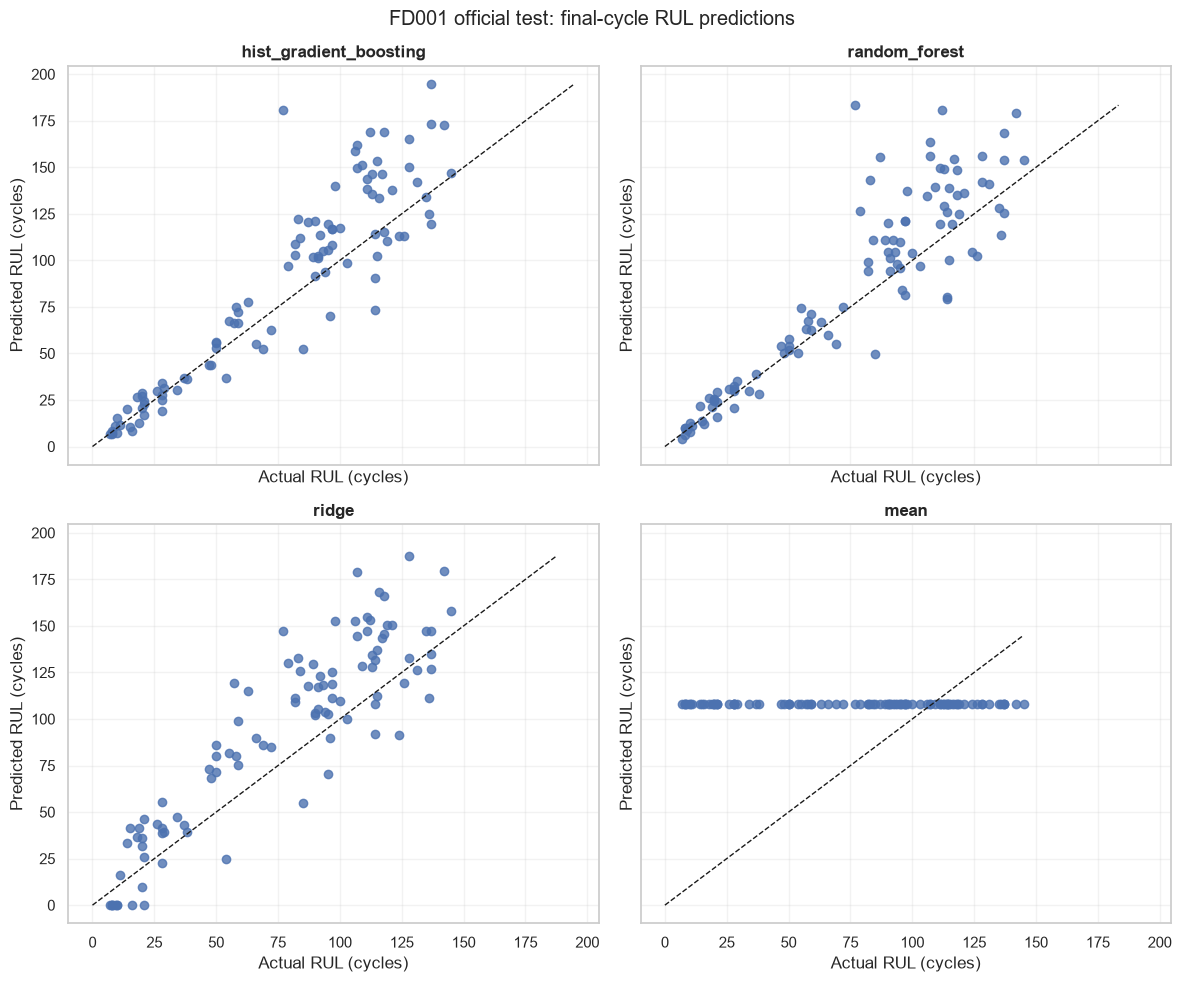

Saved official-test metrics and per-engine predictions under: C:\Users\devan\Downloads\casestudy1sol\artifacts\FD001
Official test RUL labels were used only for this final scoring step.


In [15]:
from evaluate_test import evaluate_saved_models_on_official_test

fd001_artifact_dirs = fd001_baseline_results["artifact_dir"].tolist()
fd001_test_metrics, fd001_test_predictions = evaluate_saved_models_on_official_test(
    fd001_artifact_dirs,
    data_dir=PROJECT_ROOT / "CMAPSSData",
    subset="FD001",
)

fd001_test_metrics = fd001_test_metrics.sort_values("rmse").reset_index(drop=True)
display(fd001_test_metrics[["model", "samples", "rmse", "mae", "nasa_score", "nasa_score_mean"]])
display(fd001_test_predictions.sort_values(["model", "unit"]).reset_index(drop=True))

artifact_root = PROJECT_ROOT / "artifacts" / "FD001"
artifact_root.mkdir(parents=True, exist_ok=True)
fd001_test_metrics.to_csv(artifact_root / "official_test_metrics.csv", index=False)
fd001_test_predictions.to_csv(artifact_root / "official_test_predictions.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
for ax, model_name in zip(axes.flat, fd001_test_metrics["model"]):
    model_rows = fd001_test_predictions.loc[
        fd001_test_predictions["model"] == model_name
    ]
    ax.scatter(model_rows["actual_rul"], model_rows["predicted_rul"], alpha=0.8)
    upper = max(model_rows["actual_rul"].max(), model_rows["predicted_rul"].max())
    ax.plot([0, upper], [0, upper], "k--", linewidth=1)
    ax.set_title(model_name)
    ax.set_xlabel("Actual RUL (cycles)")
    ax.set_ylabel("Predicted RUL (cycles)")
    ax.grid(alpha=0.25)
fig.suptitle("FD001 official test: final-cycle RUL predictions")
fig.tight_layout()
plt.show()

print("Saved official-test metrics and per-engine predictions under:", artifact_root)
print("Official test RUL labels were used only for this final scoring step.")

## Requested model comparison: TinyML, autoencoder, hybrid, and AFICv

The compact RUL regressor preserves the supplied TinyML paper's small 20-to-10 dense structure but uses a continuous RUL output. The hybrid shares that encoder with a reconstruction head. The AFICv Random Forest follows the supplied C-MAPSS paper's feature-selection idea. All fitting uses training engines only; the official FD001 test labels are read only in the final scoring call.

In [ ]:
from approaches.tinyml import measure_tinyml
from evaluate_test import evaluate_saved_models_on_official_test
from train_models import load_saved_model, train_models
from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
baseline_runs = train_models(data_dir=PROJECT_ROOT / 'CMAPSSData', subset='FD001', reuse=True)

tiny_hybrid_runs = train_models(
    data_dir=PROJECT_ROOT / 'CMAPSSData', subset='FD001',
    models=('tinyml_rul', 'hybrid_tinyml_autoencoder_rul'),
    epochs=60, batch_size=256, learning_rate=1e-3, reuse=True,
)
autoencoder_run = train_models(
    data_dir=PROJECT_ROOT / 'CMAPSSData', subset='FD001', models=('autoencoder',),
    epochs=30, batch_size=256, hidden_size=32, learning_rate=1e-3, reuse=True,
)
aficv_run = train_models(
    data_dir=PROJECT_ROOT / 'CMAPSSData', subset='FD001', models=('random_forest',),
    aficv_threshold=0.70, reuse=True,
)
advanced_runs = pd.concat([tiny_hybrid_runs, autoencoder_run, aficv_run], ignore_index=True)
display(advanced_runs[['model', 'artifact_dir', 'validation_metrics']])

# C-MAPSS has no cycle-level anomaly labels, so the autoencoder reports a health signal.
autoencoder_metrics = json.loads(autoencoder_run.loc[0, 'validation_metrics'])
display(pd.DataFrame([autoencoder_metrics]))


In [ ]:
# Only RUL regressors can be scored with the official RUL test labels.
rul_runs = pd.concat([baseline_runs, tiny_hybrid_runs, aficv_run], ignore_index=True)
comparison_metrics, comparison_predictions = evaluate_saved_models_on_official_test(
    rul_runs['artifact_dir'].tolist(), data_dir=PROJECT_ROOT / 'CMAPSSData', subset='FD001'
)
aficv_directory = str(aficv_run.loc[0, 'artifact_dir'])
comparison_metrics['model_display'] = comparison_metrics.apply(
    lambda row: 'AFICv Random Forest' if row['artifact_dir'] == aficv_directory else row['model'], axis=1
)
comparison_metrics = comparison_metrics.sort_values('rmse').reset_index(drop=True)
display(comparison_metrics[[
    'model_display', 'samples', 'rmse', 'mae', 'median_absolute_error', 'r2',
    'mape_percent', 'smape_percent', 'bias_predicted_minus_actual',
    'overprediction_count', 'underprediction_count', 'nasa_score', 'nasa_score_mean'
]])
best_rul_model = comparison_metrics.iloc[0]
print(f"Best FD001 RUL model by RMSE: {best_rul_model['model_display']} | RMSE={best_rul_model['rmse']:.3f}, MAE={best_rul_model['mae']:.3f}, R2={best_rul_model['r2']:.3f}")

artifact_root = PROJECT_ROOT / 'artifacts' / 'FD001'
comparison_metrics.to_csv(artifact_root / 'advanced_model_comparison.csv', index=False)
comparison_predictions.to_csv(artifact_root / 'advanced_model_predictions.csv', index=False)


In [ ]:
# Local CPU size/latency comparison for the TinyML-style inference network.
# This is not an ESP32 power/RAM measurement.
tiny_model, _ = load_saved_model(tiny_hybrid_runs.loc[tiny_hybrid_runs['model'] == 'tinyml_rul', 'artifact_dir'].iloc[0])
tinyml_measurement = measure_tinyml(
    tiny_model.network, np.zeros((1, len(tiny_model.feature_names)), dtype=np.float32), repeats=100
)
display(pd.DataFrame([tinyml_measurement]))
pd.DataFrame([tinyml_measurement]).to_csv(artifact_root / 'tinyml_deployment_measurements.csv', index=False)
